# Step 1: Prepare EF5 basic grids

Create elevation, flow direction, and flow accumulation grids for the Ghana example.
Run from `Example/Example_notebooks` with the **EF5 Builder** kernel.

The example paths use HydroSHEDS data in `Example/useful_datasets`. If needed,
download and unzip the [DEM](https://data.hydrosheds.org/file/hydrosheds-v1-dem/hyd_af_dem_30s.zip),
[flow direction](https://data.hydrosheds.org/file/hydrosheds-v1-dir/hyd_af_dir_30s.zip), and
[flow accumulation](https://data.hydrosheds.org/file/hydrosheds-v1-acc/hyd_af_acc_30s.zip) files.

Author — Vanessa Robledo (vrobledodelgado@uiowa.edu).


In [15]:
from pathlib import Path
from ef5_builder import prepare_hydrosheds, prepare_from_dem


## Set your input files

Update the paths below. Choose `"hydrosheds"` for existing drainage layers or
`"dem"` to calculate them from elevation. Use EPSG:4326 rasters and a polygon
file for your study area. [Input requirements](../../docs/basic_grids.md).


In [9]:
method = "hydrosheds"  # or "dem"

dem = Path("../useful_datasets/hydrosheds_files/hyd_af_dem_30s/hyd_af_dem_30s.tif")
facc = Path("../useful_datasets/hydrosheds_files/hyd_af_acc_30s/hyd_af_acc_30s.tif")  # only required for HydroSHEDS
fdir = Path("../useful_datasets/hydrosheds_files/hyd_af_dir_30s/hyd_af_dir_30s.tif")  # only required for HydroSHEDS
region = Path("../useful_datasets/ghana_shp/Ghana_SR.shp")  # or region.shp

output_dir = Path("../data_model/basic")
output_dir.mkdir(parents=True, exist_ok=True)

## Create the basic grids

Run the selected workflow to write `dem.tif`, `ddm.tif`, and `fam.tif`.
Supply a DEM covering the full upstream catchment. Set `region=None` to use
the full input extent, or `overwrite=True` to replace earlier outputs.


In [10]:
if method == "hydrosheds":
    outputs = prepare_hydrosheds(dem, facc, fdir, region, output_dir)
elif method == "dem":
    outputs = prepare_from_dem(dem, region, output_dir)
else:
    raise ValueError("method must be hydrosheds or dem")
outputs

{'dem': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basic/dem.tif'),
 'fdir': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basic/ddm.tif'),
 'facc': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basic/fam.tif')}

## Inspect the outputs

Check the maps and printed file information before continuing.
The preview uses fewer pixels to keep plotting fast.


dem (1216, 916) EPSG:4326 (0.00833333333333333, 0.00833333333333333) ('float32',) NoData: -9999.0
fdir (1216, 916) EPSG:4326 (0.00833333333333333, 0.00833333333333333) ('float32',) NoData: -9999.0
facc (1216, 916) EPSG:4326 (0.00833333333333333, 0.00833333333333333) ('float32',) NoData: -9999.0


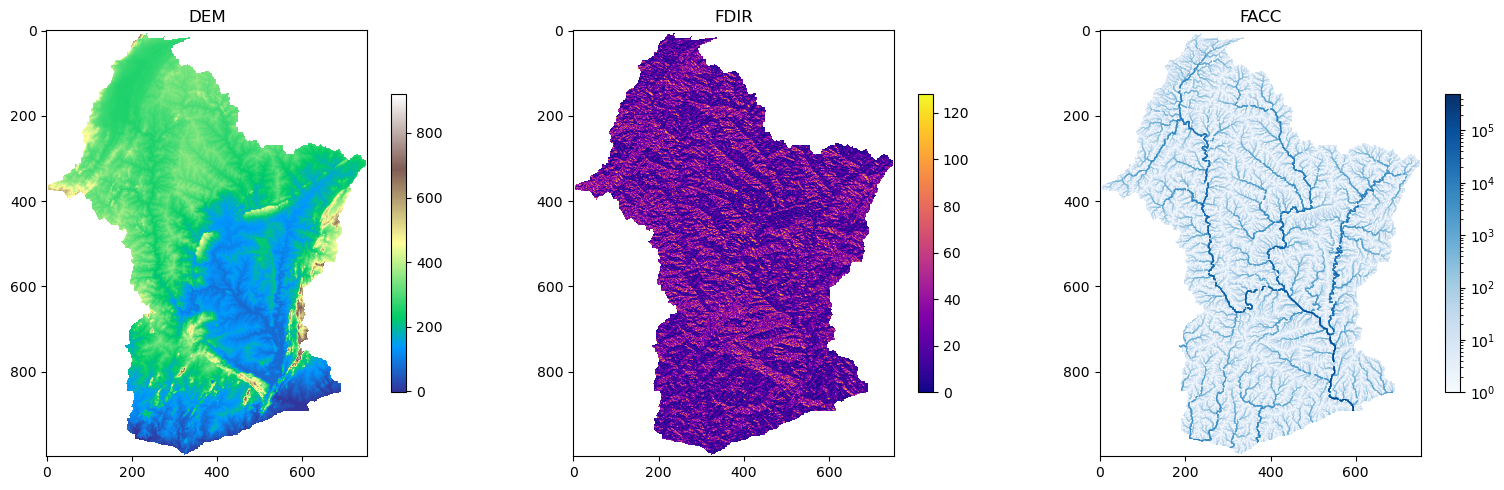

In [11]:
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, key, cmap in zip(axes, ["dem", "fdir", "facc"], ["terrain", "plasma", "Blues"]):
    with rasterio.open(outputs[key]) as src:
        print(key, src.shape, src.crs, src.res, src.dtypes, "NoData:", src.nodata)
        scale = min(1, 1000 / max(src.shape))
        image = src.read(1, masked=True, out_shape=(max(1, int(src.height * scale)), max(1, int(src.width * scale))))
    norm = LogNorm(vmin=1, vmax=max(2, float(image.max()))) if key == "facc" else None
    plot = ax.imshow(image, cmap=cmap, norm=norm)
    ax.set_title(key.upper())
    fig.colorbar(plot, ax=ax, shrink=0.7)
plt.tight_layout()

## EF5 control file

Copy the printed block into your control file. For this example,
`SelfFAM=true` means the accumulation count includes the current cell.
[EF5 settings](../../docs/basic_grids.md#outputs-and-ef5-settings).


In [14]:
print(f"[Basic]\nDEM={outputs['dem']}\nDDM={outputs['fdir']}\nFAM={outputs['facc']}\nPROJ=geographic\nESRIDDM=true\nSelfFAM=true")

[Basic]
DEM=/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basic/dem.tif
DDM=/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basic/ddm.tif
FAM=/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basic/fam.tif
PROJ=geographic
ESRIDDM=true
SelfFAM=true
